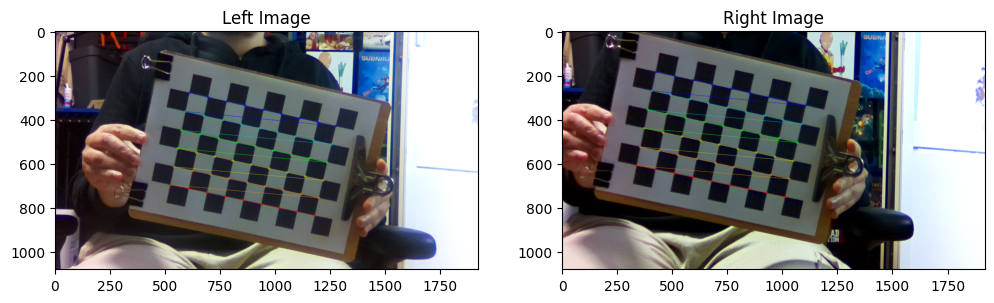

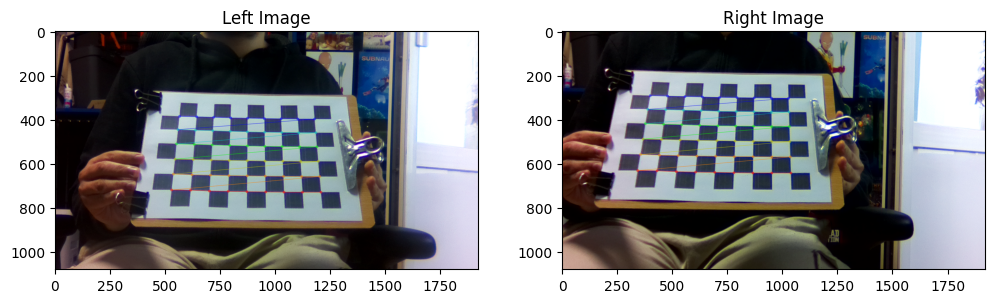

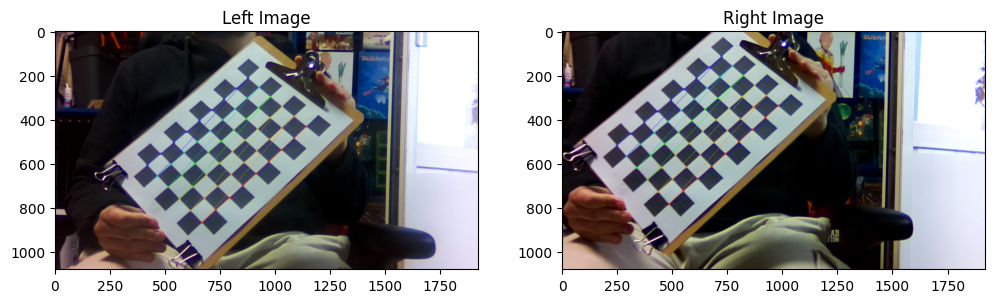

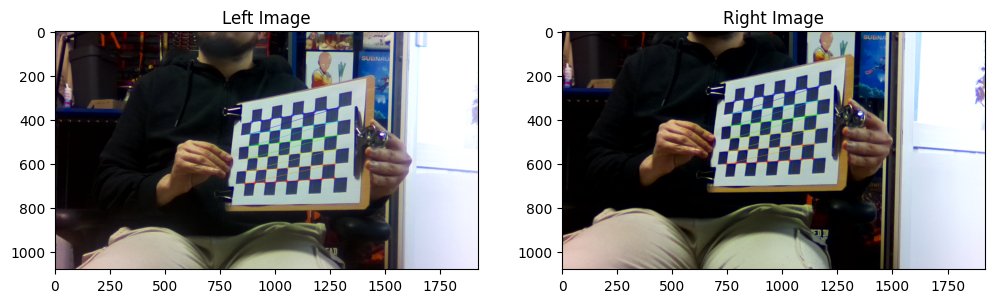

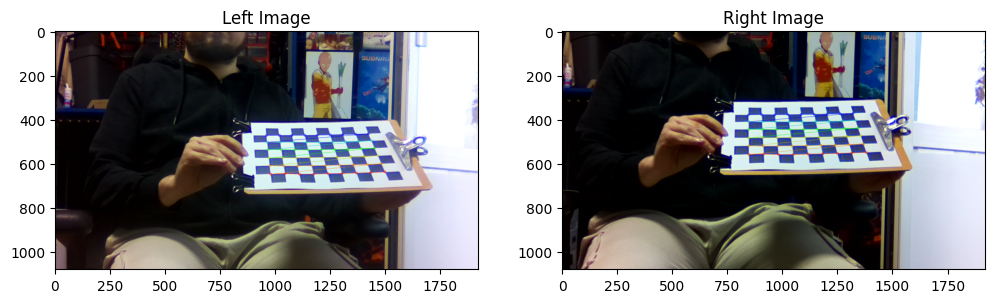

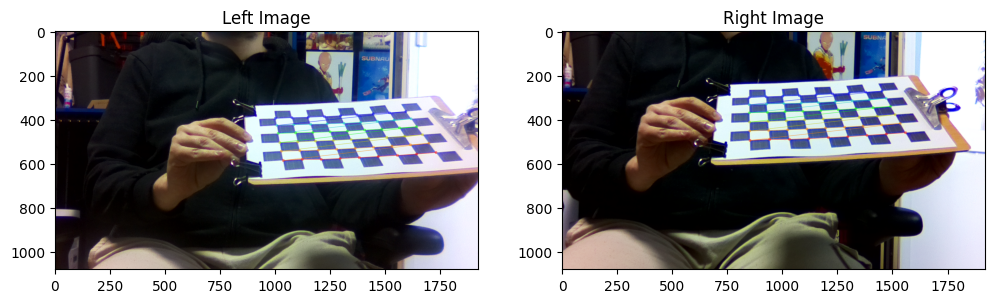

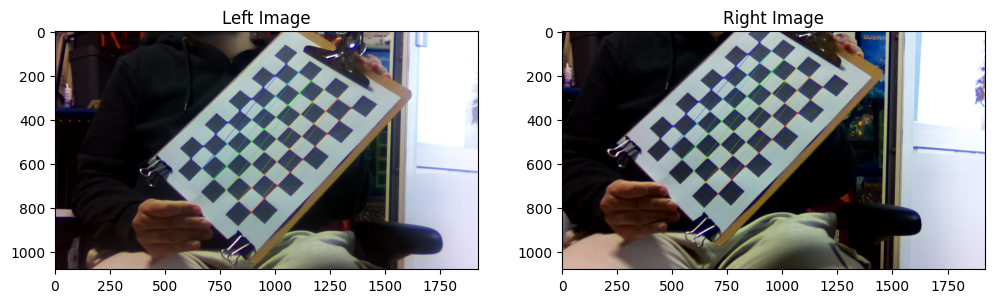

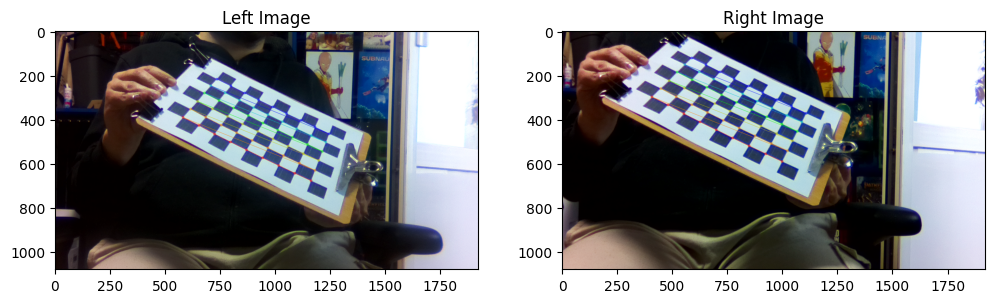

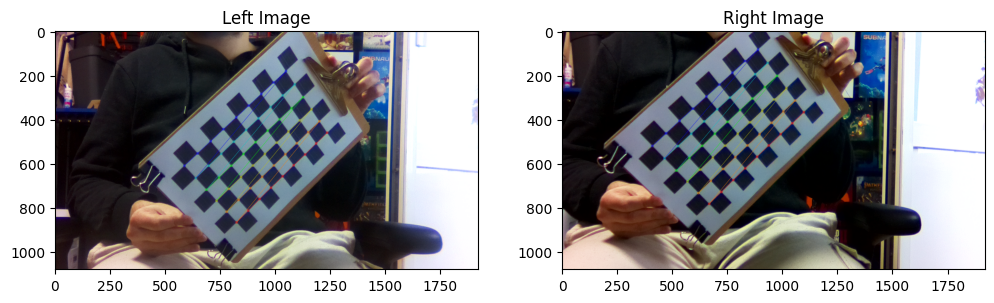

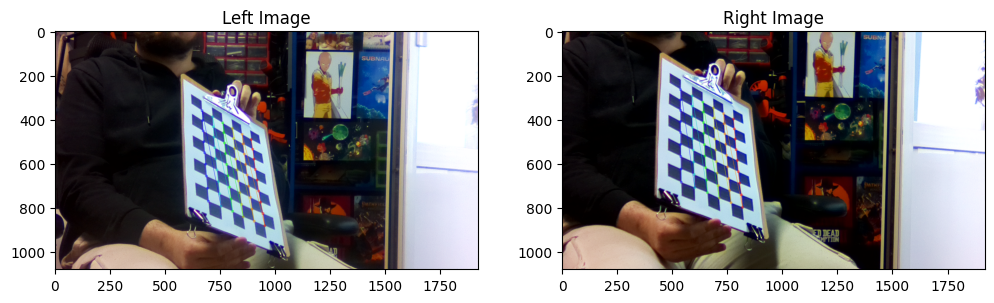

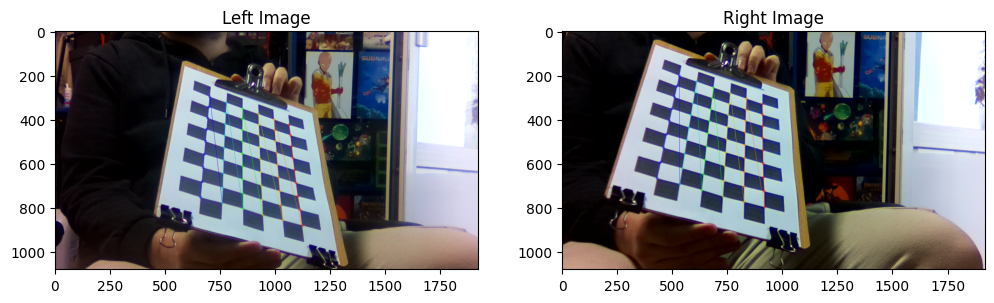

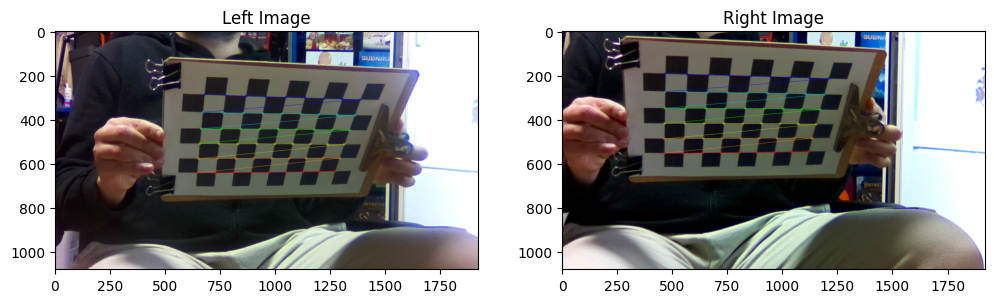

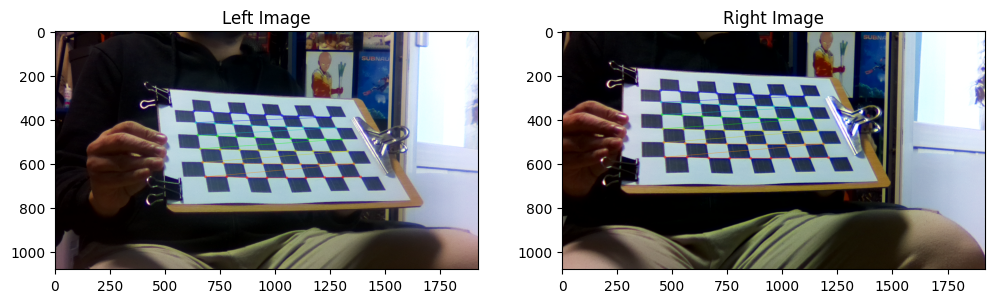

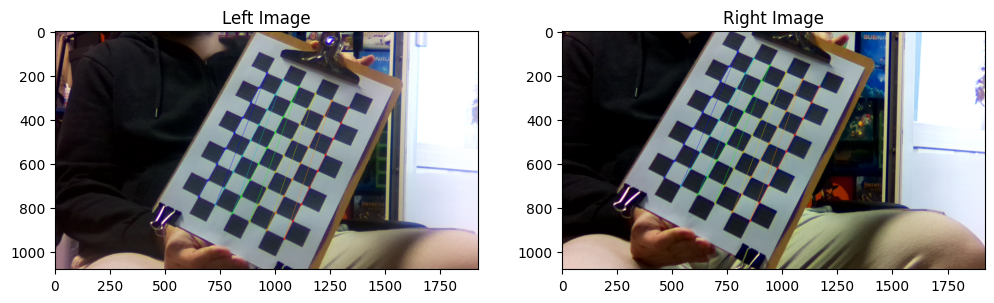

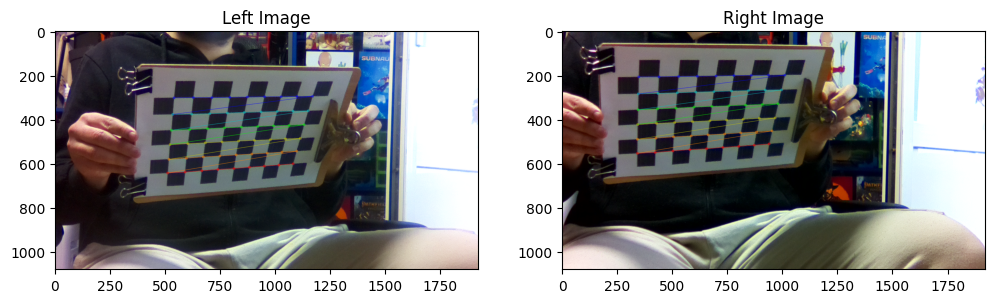

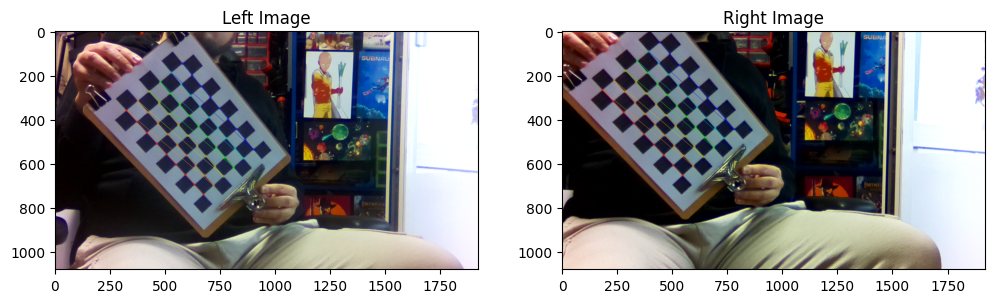

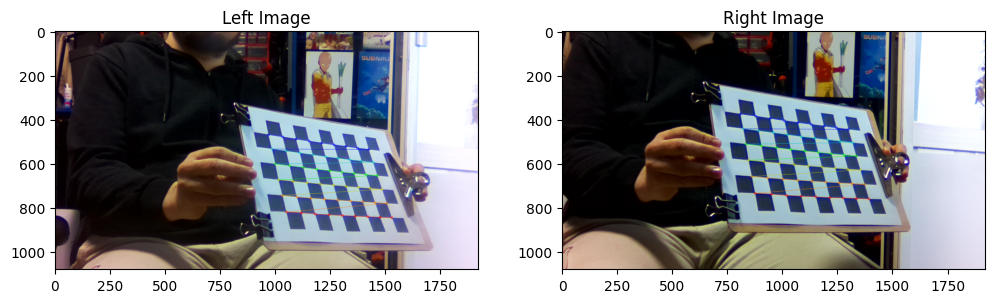

Left camera matrix:
 [[2.26509504e+03 0.00000000e+00 9.74389240e+02]
 [0.00000000e+00 2.28465920e+03 4.15872833e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Left distortion coefficients:
 [[-0.01423108  1.33865175 -0.04253941  0.00397398 -3.12818433]]

Right camera matrix:
 [[2.31261620e+03 0.00000000e+00 9.86320603e+02]
 [0.00000000e+00 2.32380493e+03 3.10538851e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Right distortion coefficients:
 [[-7.08876063e-02  1.36555558e-01 -2.95380781e-02  2.33155081e-04
   2.47312284e+00]]

Rotation matrix:
 [[ 0.99994696  0.00412173  0.00943821]
 [-0.00416176  0.99998241  0.00422572]
 [-0.00942063 -0.00426478  0.99994653]]

Translation vector:
 [[-0.06064682]
 [ 0.00049542]
 [-0.00183257]]


In [4]:
import cv2
import numpy as np
import glob
import matplotlib.pyplot as plt

# Termination criteria for the corner sub-pixel accuracy
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

# Prepare grid dimensions and square size in the real world (e.g., in meters)
chessboard_size = (9, 6)  # Number of internal corners per a chessboard row and column
square_size = 0.025  # Size of a square in meters

# Prepare object points (0,0,0), (1,0,0), (2,0,0), ..., (8,5,0)
objp = np.zeros((chessboard_size[0] * chessboard_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:chessboard_size[0], 0:chessboard_size[1]].T.reshape(-1, 2)
objp *= square_size

# Arrays to store object points and image points from all images
objpoints = []  # 3D points in real world space
imgpoints_left = []  # 2D points in left image plane
imgpoints_right = []  # 2D points in right image plane

# Get lists of calibration images
left_images = sorted(glob.glob('IMX219_stereo/left/*.png'))
right_images = sorted(glob.glob('IMX219_stereo/right/*.png'))

# Ensure we have matching pairs
assert len(left_images) == len(right_images), "Number of left and right images must match"

for left_fname, right_fname in zip(left_images, right_images):
    # Read both images
    left_img = cv2.imread(left_fname)
    right_img = cv2.imread(right_fname)
    
    left_gray = cv2.cvtColor(left_img, cv2.COLOR_BGR2GRAY)
    right_gray = cv2.cvtColor(right_img, cv2.COLOR_BGR2GRAY)

    # Find the chessboard corners in both images
    ret_left, corners_left = cv2.findChessboardCorners(left_gray, chessboard_size, None)
    ret_right, corners_right = cv2.findChessboardCorners(right_gray, chessboard_size, None)

    # If found in both images, add object points and image points
    if ret_left and ret_right:
        objpoints.append(objp)

        # Refine corners
        corners_left_refined = cv2.cornerSubPix(left_gray, corners_left, (11, 11), (-1, -1), criteria)
        corners_right_refined = cv2.cornerSubPix(right_gray, corners_right, (11, 11), (-1, -1), criteria)
        
        imgpoints_left.append(corners_left_refined)
        imgpoints_right.append(corners_right_refined)

        # Draw and display the corners for both images
        cv2.drawChessboardCorners(left_img, chessboard_size, corners_left_refined, ret_left)
        cv2.drawChessboardCorners(right_img, chessboard_size, corners_right_refined, ret_right)
        
        plt.figure(figsize=(12,5))
        plt.subplot(121)
        plt.imshow(cv2.cvtColor(left_img, cv2.COLOR_BGR2RGB))
        plt.title('Left Image')
        plt.subplot(122)
        plt.imshow(cv2.cvtColor(right_img, cv2.COLOR_BGR2RGB))
        plt.title('Right Image')
        plt.show()
    else:
        print(f"Pattern not found for {(left_fname, right_fname)}")

# First calibrate left camera
ret_left, mtx_left, dist_left, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints_left, left_gray.shape[::-1], None, None)

# Then calibrate right camera
ret_right, mtx_right, dist_right, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints_right, right_gray.shape[::-1], None, None)

# Finally do stereo calibration with the individual results
ret, mtx_left, dist_left, mtx_right, dist_right, R, T, E, F = cv2.stereoCalibrate(
    objpoints, imgpoints_left, imgpoints_right,
    mtx_left, dist_left,
    mtx_right, dist_right,
    left_gray.shape[::-1],
    criteria=criteria,
    flags=cv2.CALIB_FIX_INTRINSIC
)

# Print the calibration results
print("Left camera matrix:\n", mtx_left)
print("\nLeft distortion coefficients:\n", dist_left)
print("\nRight camera matrix:\n", mtx_right)
print("\nRight distortion coefficients:\n", dist_right)
print("\nRotation matrix:\n", R)
print("\nTranslation vector:\n", T)

# Save the stereo calibration results
np.savez('../../calibration/IMX219_stereo.npz',
         mtx_left=mtx_left, dist_left=dist_left,
         mtx_right=mtx_right, dist_right=dist_right,
         R=R, T=T, E=E, F=F)

In [21]:
ret_left

0.9840943269424439

In [22]:
ret_right

1.0884916586882132

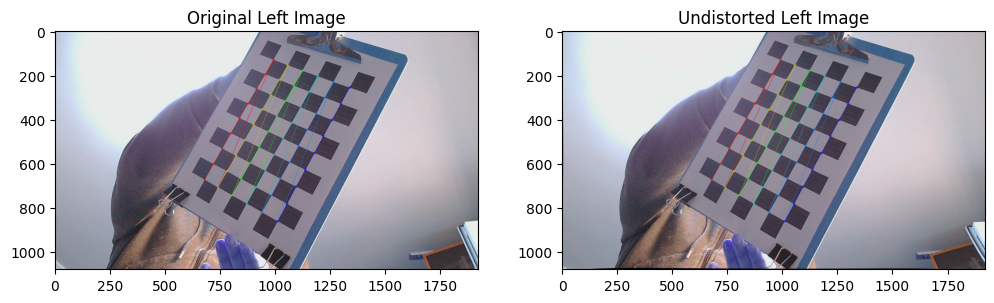

In [23]:
undistorted = cv2.undistort(left_img, mtx_left, dist_left)
# show
plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(left_img)
plt.title('Original Left Image')
plt.subplot(122) 
plt.imshow(undistorted)
plt.title('Undistorted Left Image')
plt.show()

